In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)


In [3]:

# 1. Load the dataset
df = pd.read_csv("heart_v2.csv")

# 2. Exploratory Data Analysis
print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
print(df.describe())

print("\nClass distribution:")
print(df["heart disease"].value_counts().sort_index())

print("\nClass percentages:")
print(
    (
        df["heart disease"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)


First five rows:
   age  sex   BP  cholestrol  heart disease
0   70    1  130         322              1
1   67    0  115         564              0
2   57    1  124         261              1
3   64    1  128         263              0
4   74    0  120         269              0

Dataset shape: (270, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   age            270 non-null    int64
 1   sex            270 non-null    int64
 2   BP             270 non-null    int64
 3   cholestrol     270 non-null    int64
 4   heart disease  270 non-null    int64
dtypes: int64(5)
memory usage: 10.7 KB

Missing values:
age              0
sex              0
BP               0
cholestrol       0
heart disease    0
dtype: int64

Summary statistics:
              age         sex          BP  cholestrol  heart disease
count  270.000000  2

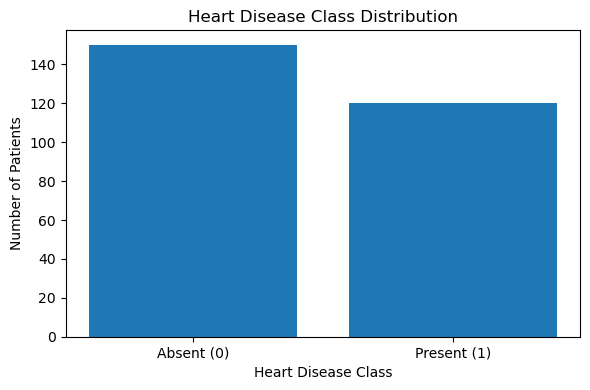

In [4]:

# 3. Plot class distribution
counts = df["heart disease"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Absent (0)", "Present (1)"], counts.values)
plt.xlabel("Heart Disease Class")
plt.ylabel("Number of Patients")
plt.title("Heart Disease Class Distribution")
plt.tight_layout()
plt.show()


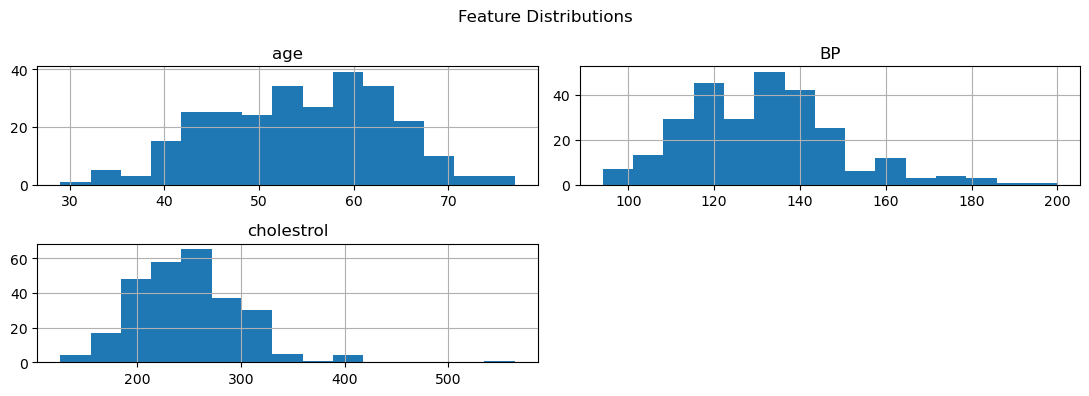


Average measurements by disease class:
                 age      BP  cholestrol
heart disease                           
0              52.71  128.87      244.21
1              56.59  134.44      256.47


In [5]:

# 4. Plot feature distributions
df[["age", "BP", "cholestrol"]].hist(
    bins=15,
    figsize=(11, 4)
)

plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

# Compare average measurements by disease class
print("\nAverage measurements by disease class:")
print(
    df.groupby("heart disease")[
        ["age", "BP", "cholestrol"]
    ].mean().round(2)
)


In [6]:

# 5. Separate features and target
X = df.drop(columns=["heart disease"])
y = df["heart disease"]



Training samples: 216
Testing samples: 54

Model Performance:
Accuracy: 0.6852
Precision: 0.6207
Recall: 0.7500
F1 Score: 0.6792

Confusion Matrix:
[[19 11]
 [ 6 18]]

Actual vs Predicted:
    Actual Predicted
0   Absent    Absent
1   Absent    Absent
2   Absent   Present
3  Present   Present
4   Absent   Present
5   Absent    Absent
6   Absent   Present
7  Present   Present
8  Present   Present
9  Present    Absent


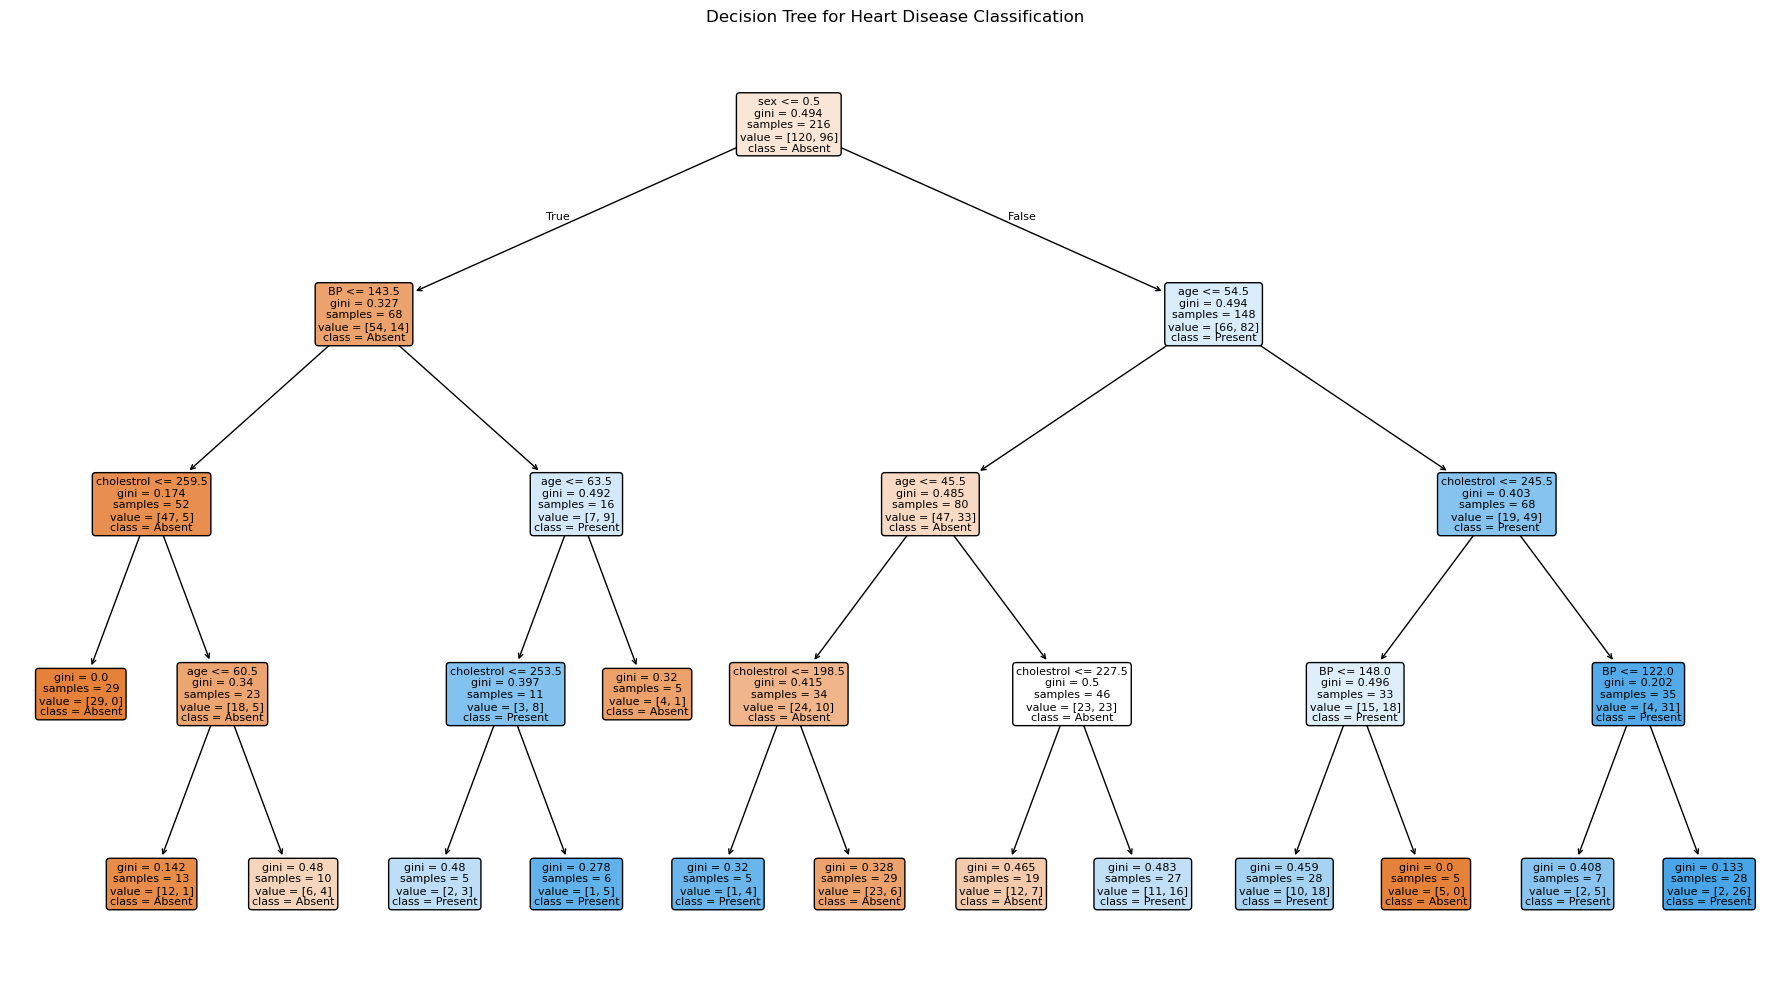

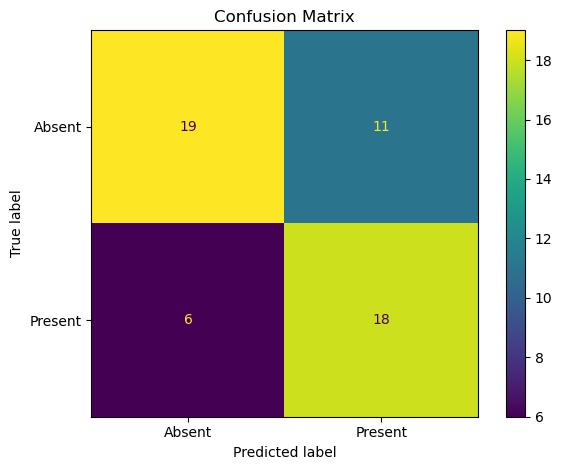


Feature Importance:
age           0.279674
sex           0.269414
cholestrol    0.228091
BP            0.222820
dtype: float64


In [7]:

# 6. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 7. Create the Decision Tree classifier
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

# 8. Train the model
model.fit(X_train, y_train)

# 9. Predict disease classes
y_pred = model.predict(X_test)

# 10. Evaluate model performance
print("\nModel Performance:")

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(cm)

# 11. Display actual vs predicted results
results = pd.DataFrame({
    "Actual": y_test.map({
        0: "Absent", 1: "Present"
    }).to_numpy(),
    "Predicted": pd.Series(y_pred).map({
        0: "Absent", 1: "Present"
    }).to_numpy()
})

print("\nActual vs Predicted:")
print(results.head(10))

# 12. Visualize the Decision Tree
plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Absent", "Present"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Heart Disease Classification")
plt.tight_layout()
plt.show()

# 13. Visualize the Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Absent", "Present"]
)

disp.plot()
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# 14. Display feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)
